In [1]:
# Standard Libraries

import os
import gc
import random
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")


# Data Manipulation

import numpy as np
import pandas as pd


# Visualization

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8")
sns.set_palette("Set2")

# Machine Learning Models

import tensorflow as tf
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


# Evaluation


from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# TensorFlow

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import regularizers

In [2]:
# Project Configuration

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

FIGSIZE = (12,6)

print("TensorFlow Version :", tf.__version__)
print("NumPy Version      :", np.__version__)
print("Pandas Version     :", pd.__version__)

TensorFlow Version : 2.21.0
NumPy Version      : 2.4.6
Pandas Version     : 3.0.5


# Load data from disk

In [9]:
DATA_DIR = Path("data/Training_Datasets")
RESULT_DIR = Path('Results')

# -----------------------------
# Features
# -----------------------------
# X_train_scaled = pd.read_csv(DATA_DIR / "X_train_scaled.csv")
# X_valid_scaled = pd.read_csv(DATA_DIR / "X_valid_scaled.csv")
# X_test_scaled  = pd.read_csv(DATA_DIR / "X_test_scaled.csv")

X_train_tree = pd.read_csv(DATA_DIR / "X_train_tree.csv")
X_valid_tree = pd.read_csv(DATA_DIR / "X_valid_tree.csv")
X_test_tree  = pd.read_csv(DATA_DIR / "X_test_tree.csv")

# -----------------------------
# Targets
# -----------------------------
y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze("columns")
y_valid = pd.read_csv(DATA_DIR / "y_valid.csv").squeeze("columns")
y_test  = pd.read_csv(DATA_DIR / "y_test.csv").squeeze("columns")

# -----------------------------
# Restults
# -----------------------------

all_val_results = pd.read_csv(RESULT_DIR/"all_models_results.csv")

print("Datasets loaded successfully.")

Datasets loaded successfully.


# Explainable AI (SHAP)

## Why Explainability?

Financial fraud detection is a high-stakes application where model transparency is important for:

* Model debugging
* Building stakeholder trust
* Understanding fraud patterns
* Supporting audit and compliance requirements
* Validating feature engineering decisions

SHAP (SHapley Additive exPlanations) has become one of the most widely used methods for explaining tree-based machine learning models because it provides both **global** and **local** feature attributions.

# 13.1 Select the Best Model

Earlier we stored the best-performing model.

For demonstration, let's assume **LightGBM** achieved the highest PR-AUC.

In [25]:

# Load All Saved Models


from pathlib import Path
import joblib
from tensorflow.keras.models import load_model

MODEL_DIR = Path("models")

# Load ML models
# lr_model = joblib.load(MODEL_DIR / "logistic_regression.joblib")
# dt_model = joblib.load(MODEL_DIR / "decision_tree.joblib")
# rf_model = joblib.load(MODEL_DIR / "random_forest.joblib")
# xgb_model = joblib.load(MODEL_DIR / "xgboost.joblib")
lgbm_model = joblib.load(MODEL_DIR / "lightgbm.joblib")
# cat_model = joblib.load(MODEL_DIR / "catboost.joblib")

# Load TensorFlow model
# nn_model = load_model(MODEL_DIR / "best_nn.keras")

# Load preprocessing artifacts
# preprocessing = joblib.load(MODEL_DIR / "preprocessing.joblib")

# imputer = preprocessing["imputer"]
# encoder = preprocessing["encoder"]
# scaler = preprocessing["scaler"]
# feature_columns = preprocessing["feature_columns"]
# threshold = preprocessing["threshold"]

print("✓ All models and preprocessing artifacts loaded successfully.")

✓ All models and preprocessing artifacts loaded successfully.


In [5]:

# Best Model
best_model = lgbm_model

# 13.2 Install SHAP (if needed)

In [6]:
# Uncomment if necessary

# !pip install shap

---

# 13.3 Import

In [7]:
import shap

shap.initjs()

---

# 13.4 Sample the Dataset

Never compute SHAP on the entire validation set.

It is unnecessarily slow.

Instead, sample a few thousand observations.

In [10]:
SHAP_SAMPLE_SIZE = 5000

X_shap = X_valid_tree.sample(
    n=min(
        SHAP_SAMPLE_SIZE,
        len(X_valid_tree)
    ),
    random_state=RANDOM_STATE
)

Sampling is a common practical approach because SHAP values for large datasets can be computationally expensive while a representative subset is usually sufficient for global interpretation.

# 13.5 Build Explainer

In [11]:
explainer = shap.TreeExplainer(
    best_model
)

TreeExplainer provides an efficient and exact algorithm for tree ensembles including XGBoost, LightGBM, CatBoost, and Random Forest. 

# 13.6 Compute Verify SHAP Values

In [12]:
shap_values = explainer(X_shap)

In [13]:
print(shap_values.values.shape)

print(X_shap.shape)

(5000, 436)
(5000, 436)


# 13.7 Global Feature Importance

This answers:
    Which variables contribute the most overall?

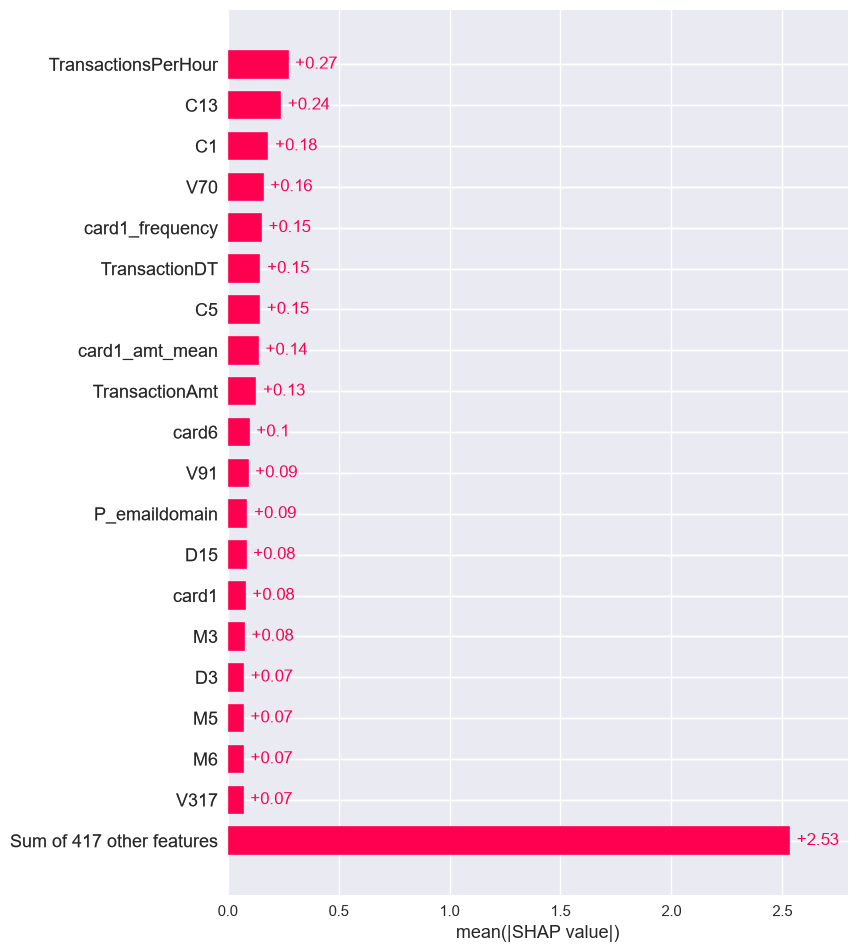

In [14]:
shap.plots.bar(
    shap_values,
    max_display=20
)

This shows:

* overall importance
* average contribution
* ranking of all features

# 13.8 SHAP Beeswarm Plot

This is arguably the most informative SHAP visualization.

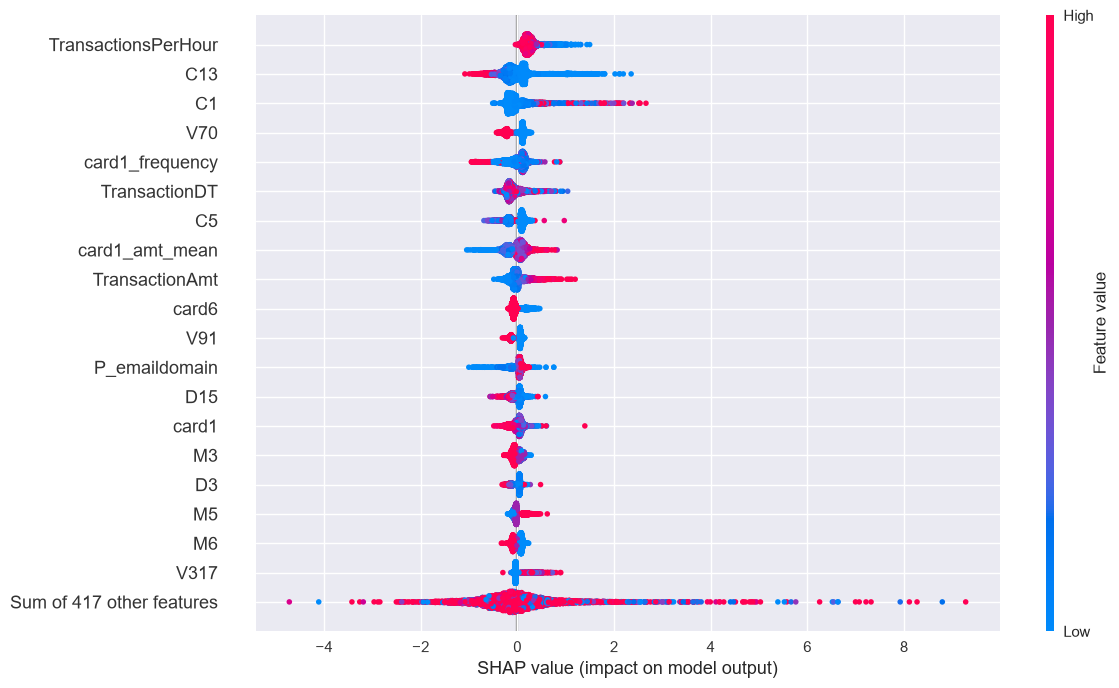

In [15]:

shap.plots.beeswarm(
    shap_values,
    max_display=20,
    plot_size=(12, 8)
)

The beeswarm plot summarizes how each feature influences predictions across many observations. Features are ordered by overall importance, while color indicates whether the original feature value is high (red) or low (blue).

# 13.9 Top 20 Features

In [16]:
importance = pd.DataFrame({

    "Feature": X_shap.columns,

    "MeanAbsSHAP":
    np.abs(
        shap_values.values
    ).mean(axis=0)

})

importance = importance.sort_values(
    "MeanAbsSHAP",
    ascending=False
)

display(
    importance.head(20)
)

,Feature,MeanAbsSHAP
428,TransactionsPerHour,0.273964
20,C13,0.240847
15,C1,0.183562
109,V70,0.161951
429,card1_frequency,0.154256
0,TransactionDT,0.147670
17,C5,0.146131
430,card1_amt_mean,0.140157
1,TransactionAmt,0.129031
8,card6,0.098958


# 13.10 SHAP Importance Plot

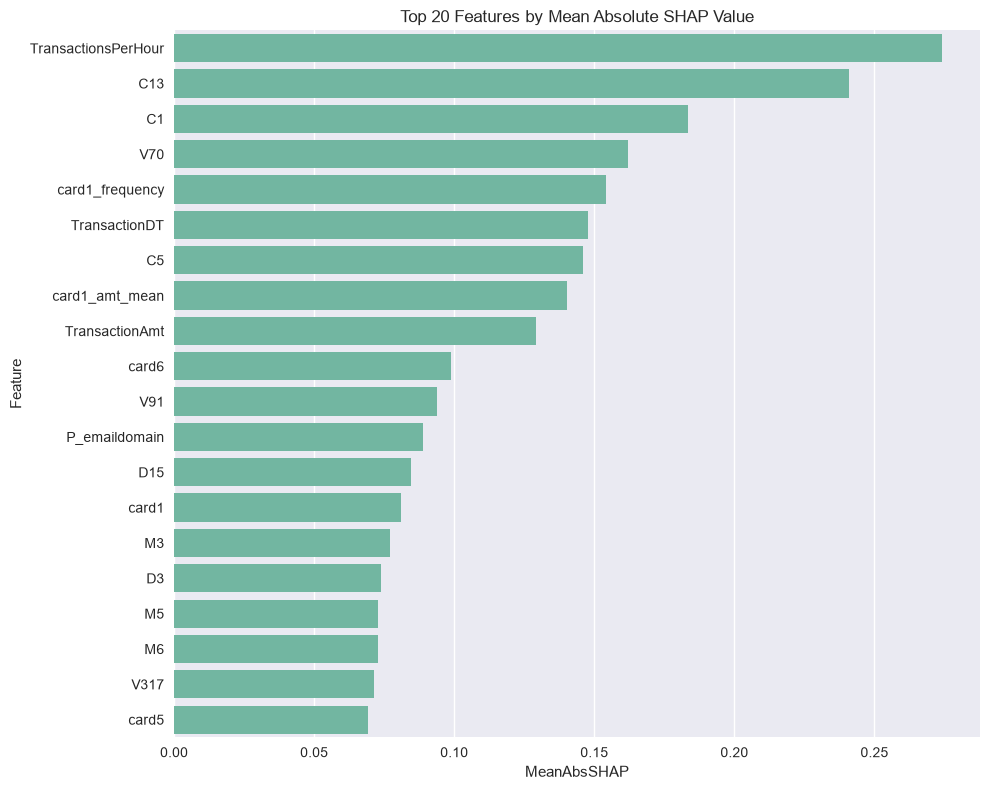

In [17]:
plt.figure(figsize=(10,8))

sns.barplot(

    data=importance.head(20),

    x="MeanAbsSHAP",

    y="Feature"

)

plt.title(
    "Top 20 Features by Mean Absolute SHAP Value"
)

plt.tight_layout()

plt.show()

# 13.11 Dependence Plot

Unlike the summary plot, dependence plots explain how a feature influences predictions.

Let's start with the most important feature.

In [18]:
TOP_FEATURE = importance.iloc[0]["Feature"]

print(TOP_FEATURE)

TransactionsPerHour


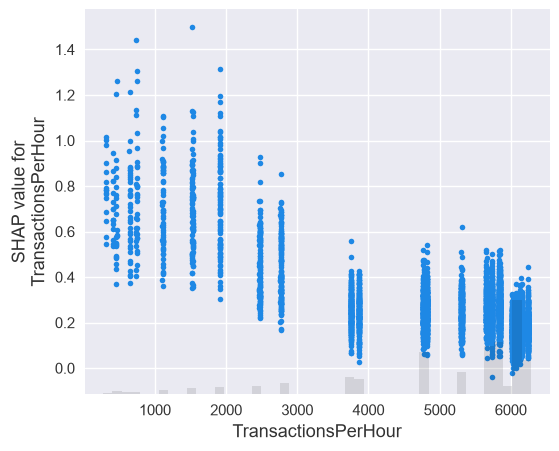

In [19]:
shap.plots.scatter(
    shap_values[:, TOP_FEATURE]
)

Dependence plots help visualize how changes in an individual feature affect the model prediction and can also reveal interactions with other features.

# 13.12 Local Explanation (Waterfall Plot)

Let's inspect one highly suspicious transaction.

In [20]:
fraud_idx = np.argmax(
    lgbm_model.predict_proba(X_shap)[:, 1]
)

print(fraud_idx)

3371


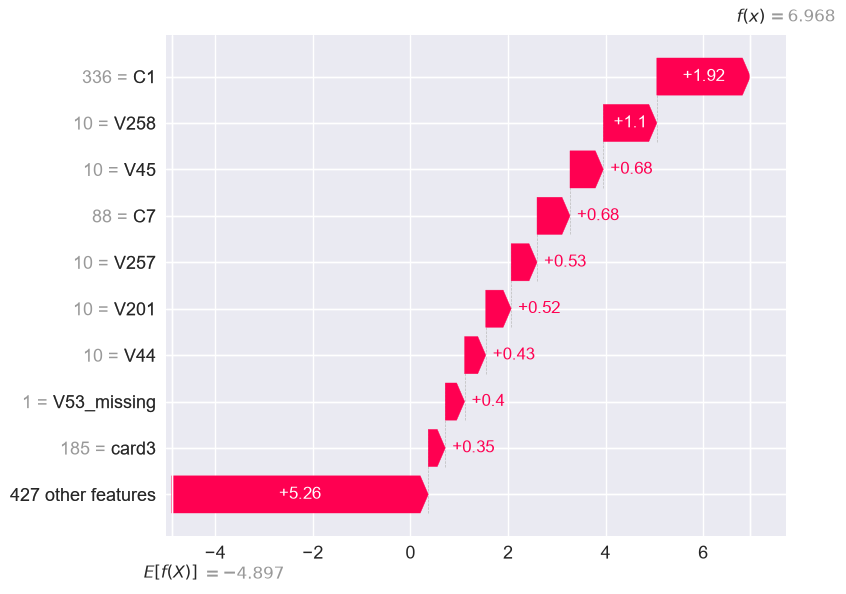

In [21]:
shap.plots.waterfall(
    shap_values[fraud_idx]
)

This plot explains why one transaction received a high fraud probability by showing how each feature pushed the prediction higher or lower.

# 13.13 Force Plot

In [22]:
shap.plots.force(
    shap_values[fraud_idx]
)

# 13.14 Explain Multiple Fraud Cases

Instead of explaining only one transaction, let's inspect the top five highest-risk predictions.

In [23]:
probabilities = lgbm_model.predict_proba(
    X_shap
)[:, 1]

top5 = np.argsort(
    probabilities
)[-5:]

top5

array([3942, 4827, 3324, 2861, 3371])

Transaction 3942


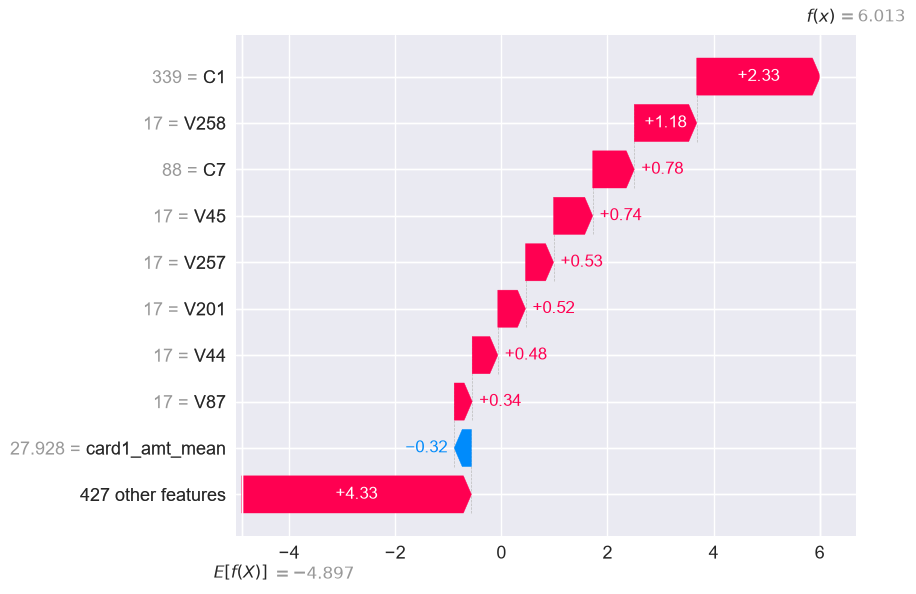

Transaction 4827


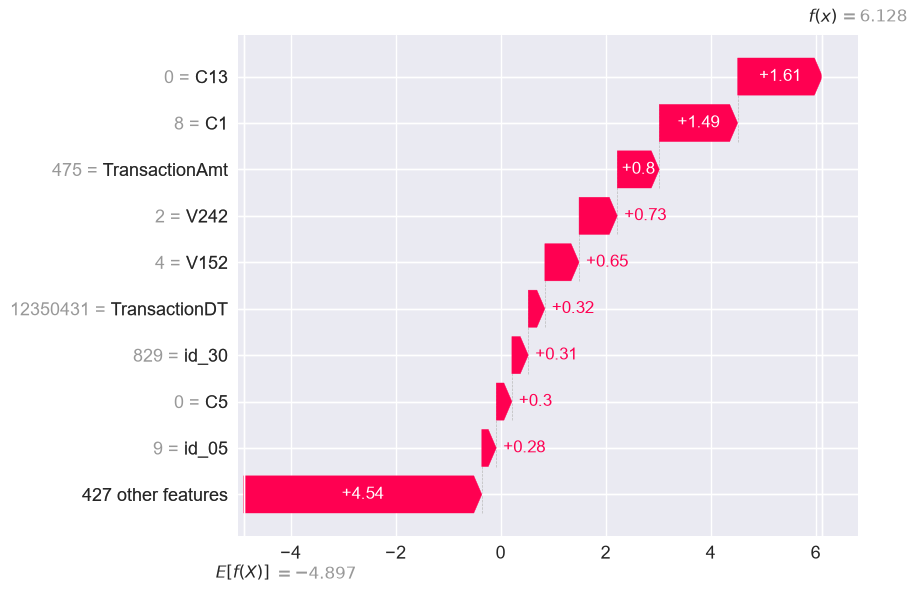

Transaction 3324


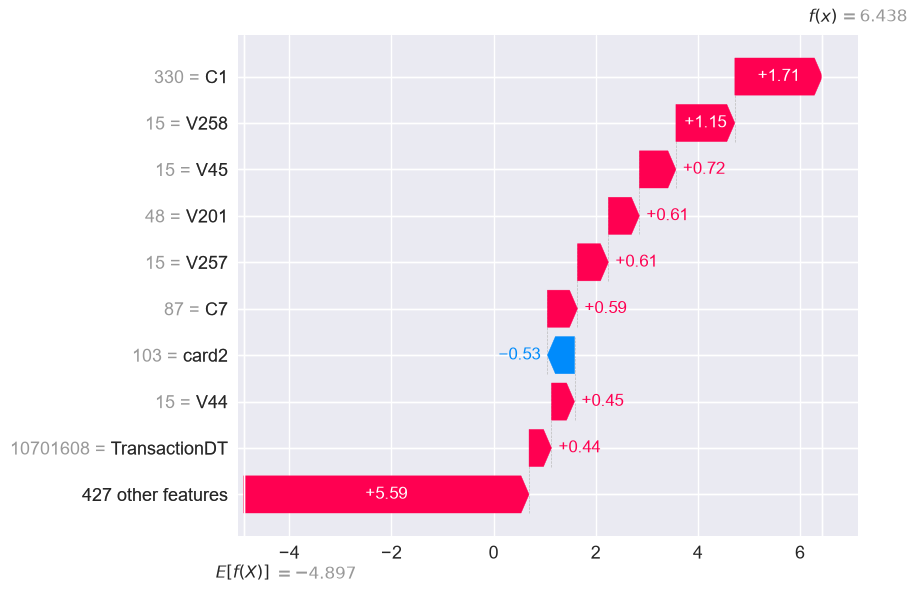

Transaction 2861


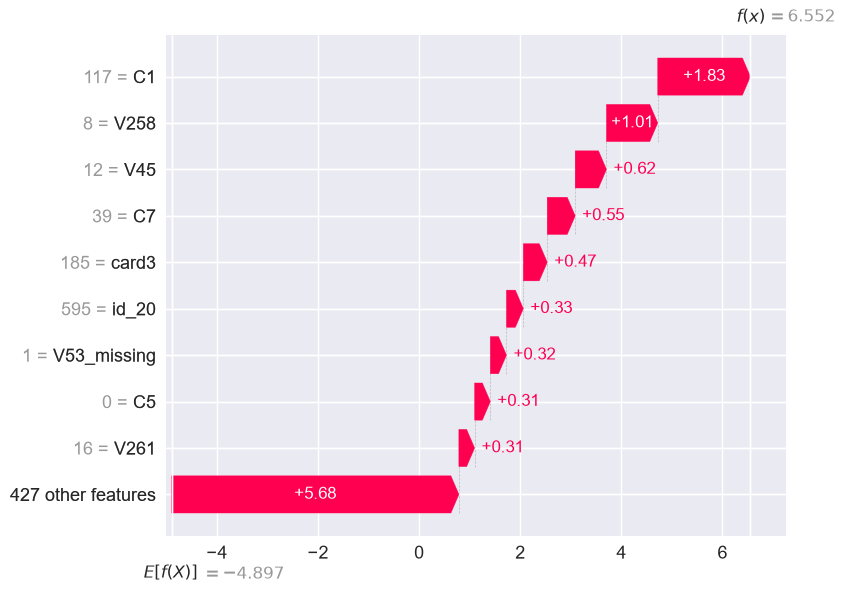

Transaction 3371


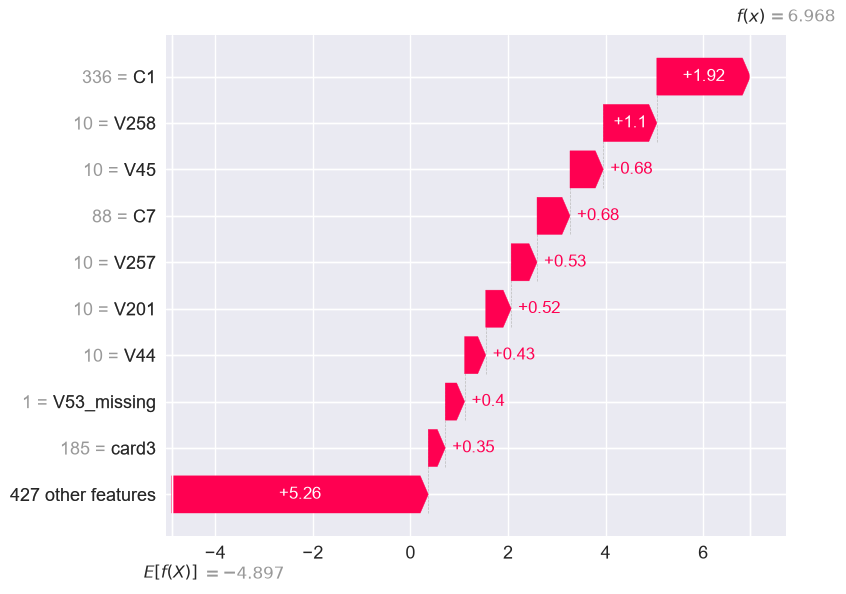

In [24]:
for idx in top5:

    print("=" * 80)

    print(f"Transaction {idx}")

    shap.plots.waterfall(
        shap_values[idx]
    )

# 13.15 SHAP Interpretation

Conclusion:
- The model relies primarily on a relatively small subset of engineered features.
- Positive SHAP values increase the predicted fraud risk, while negative values decrease it.
- The direction of impact differs across transactions, highlighting nonlinear relationships captured by LightGBM.
- Local explanations demonstrate why specific transactions were flagged, supporting model debugging and stakeholder communication.